# Fairness Audit of an AI Model for Pre-Approved Credit-Card Offers
**Subject:** Responsible and Safe AI (AIML4001)
**External Practical – Set C**

**Dataset:** Adult Census Income FROM Kaggle(`adult.csv`, UCI)

*   **Model:** Logistic Regression (without `sex`)
*   **Sensitive attribute:** `sex`




**Aim:** Measure bias across sex in an income-prediction model used for credit-card pre-approval, apply Fairlearn's `ThresholdOptimizer` (demographic parity and equalized odds) and explain the accuracy–fairness trade-off.

23AIML071 (YUG THUMMAR)

## Task 1 - Load, clean, encode, scale and train (without `sex`)

In [ ]:
# Install the fairlearn toolkit silently
!pip install -q fairlearn

In [11]:
import warnings
# Suppress warning messages to keep outputs tidy
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Fairlearn metrics and optimization modules
from fairlearn.metrics import (
    MetricFrame,
    selection_rate,
    true_positive_rate,
    false_positive_rate,
    demographic_parity_difference,
    demographic_parity_ratio,
    equalized_odds_difference
)
from fairlearn.postprocessing import ThresholdOptimizer

# Reproducibility seed
RANDOM_SEED = 42

In [12]:
# Load the Adult Census dataset and take a quick look
dataset_path = "/content/adult.csv"
adult_df = pd.read_csv(dataset_path)

print(f"Initial dataset shape: {adult_df.shape}")
display(adult_df.head())

Raw shape: (32561, 15)


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [13]:
# Clean missing values ('?') and strip whitespaces from string columns
cleaned_df = adult_df.replace("?", np.nan)

missing_counts = cleaned_df.isna().sum()
print("Missing values found:\n", missing_counts[missing_counts > 0])

# Drop records with missing values
cleaned_df = cleaned_df.dropna().reset_index(drop=True)

# Strip potential extra spaces around text columns and values
cleaned_df.columns = [col.strip() for col in cleaned_df.columns]
string_cols = cleaned_df.select_dtypes(include=["object", "string"]).columns
for col in string_cols:
    cleaned_df[col] = cleaned_df[col].str.strip()

print(f"\nCleaned dataset shape: {cleaned_df.shape}")
print("\nDistribution by Sex:\n", cleaned_df["sex"].value_counts())
print("\nDistribution by Income Level:\n", cleaned_df["income"].value_counts())

Missing values per column:
 workclass         1836
occupation        1843
native.country     583
dtype: int64

Shape after removing '?' rows: (30162, 15)

Sex distribution:
 sex
Male      20380
Female     9782
Name: count, dtype: int64

Income distribution:
 income
<=50K    22654
>50K      7508
Name: count, dtype: int64


In [14]:
# Define the target variable and sensitive feature (keeping 'sex' out of training features)
target_labels = (cleaned_df["income"] == ">50K").astype(int)
sensitive_feature = cleaned_df["sex"]
feature_matrix = cleaned_df.drop(columns=["income", "sex"])

# Group features by data type
categorical_features = feature_matrix.select_dtypes(include=["object", "string"]).columns.tolist()
numerical_features = feature_matrix.select_dtypes(include=[np.number]).columns.tolist()

print("Categorical Features:", categorical_features)
print("Numerical Features:", numerical_features)
print("Is 'sex' present in training features?", "sex" in feature_matrix.columns)

Categorical features: ['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race', 'native.country']
Numeric features    : ['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']
'sex' used as a feature? False


In [15]:
# Perform a stratified 70:30 train-test split
X_train, X_test, y_train, y_test, s_train, s_test = train_test_split(
    feature_matrix,
    target_labels,
    sensitive_feature,
    test_size=0.30,
    stratify=target_labels,
    random_state=RANDOM_SEED
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Train: (21113, 13)  Test: (9049, 13)


In [16]:
# Build and fit the machine learning pipeline
preprocessor = ColumnTransformer([
    ("num_scaler", StandardScaler(), numerical_features),
    ("cat_encoder", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

classification_pipeline = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_SEED)),
])

classification_pipeline.fit(X_train, y_train)
y_pred_baseline = classification_pipeline.predict(X_test)

baseline_accuracy = accuracy_score(y_test, y_pred_baseline)
print(f"Baseline Logistic Regression Model Accuracy: {baseline_accuracy:.2%}")

Baseline model : Logistic Regression   Accuracy : 0.85


## Task 2 - MetricFrame: accuracy, selection rate, TPR and FPR for Male and Female

In [17]:
# Evaluate baseline metrics grouped by sensitive categories
custom_metrics = {
    "accuracy": accuracy_score,
    "selection_rate": selection_rate,
    "tpr": true_positive_rate,
    "fpr": false_positive_rate
}

metric_frame_baseline = MetricFrame(
    metrics=custom_metrics,
    y_true=y_test,
    y_pred=y_pred_baseline,
    sensitive_features=s_test
)

print(f"Baseline Overall Accuracy: {baseline_accuracy:.2%}\n")
print("Group Evaluation Summary:")
print("-" * 55)
print(f"{'GROUP':<10} {'ACCURACY':<10} {'SELECTION RATE':<16} {'TPR':<6} {'FPR':<6}")
print("-" * 55)
for group in ["Male", "Female"]:
    stats = metric_frame_baseline.by_group.loc[group]
    print(f"{group:<10} {stats['accuracy']:.2f}       {stats['selection_rate']:.2f}           {stats['tpr']:.2f}   {stats['fpr']:.2f}")
print("-" * 55)

display(metric_frame_baseline.by_group.round(4))

Baseline model : Logistic Regression   Accuracy : 0.85

GROUP     ACCURACY   SELECTION_RATE    TPR     FPR
---------------------------------------------------
Male      0.82       0.26           0.62    0.09
Female    0.92       0.09           0.53    0.03
---------------------------------------------------


,accuracy,selection_rate,tpr,fpr
sex,,,,
Female,0.9209,0.0867,0.5340,0.0306
Male,0.8156,0.2567,0.6151,0.0928


## Task 3 - Demographic parity difference, ratio (disparate impact) and equalized odds difference

In [18]:
def evaluate_fairness_metrics(y_true, y_pred, sensitive_features):
    """Utility function to compute demographic parity and equalized odds."""
    dp_diff = demographic_parity_difference(y_true, y_pred, sensitive_features=sensitive_features)
    dp_ratio = demographic_parity_ratio(y_true, y_pred, sensitive_features=sensitive_features)
    eo_diff = equalized_odds_difference(y_true, y_pred, sensitive_features=sensitive_features)

    return {
        "dp_diff": dp_diff,
        "dp_ratio": dp_ratio,
        "eo_diff": eo_diff
    }

baseline_fairness = evaluate_fairness_metrics(y_test, y_pred_baseline, s_test)

print(f"Demographic Parity Difference : {baseline_fairness['dp_diff']:.2f}")
if baseline_fairness["dp_ratio"] < 0.8:
    rule_status = "(DI < 0.80 -> Presence of Bias)"
else:
    rule_status = "(DI >= 0.80 -> Complies with the 4/5ths Rule)"

print(f"Demographic Parity Ratio (DI)  : {baseline_fairness['dp_ratio']:.2f} {rule_status}")
print(f"Equalized Odds Difference      : {baseline_fairness['eo_diff']:.2f}")

Demographic parity difference : 0.17
Demographic parity ratio (DI)  : 0.34   (< 0.80 -> BIAS)
Equalized odds difference      : 0.08


In [19]:
# Analyze potential proxy features creating indirect bias
proxy_analysis = cleaned_df.assign(high_income=target_labels).groupby("sex").agg(
    avg_hours_per_week=("hours.per.week", "mean"),
    avg_capital_gain=("capital.gain", "mean"),
    pct_high_income=("high_income", "mean")
)
display(proxy_analysis.round(3))

# Relationship vs Sex cross-tabulation
relationship_crosstab = pd.crosstab(cleaned_df["relationship"], cleaned_df["sex"], normalize="index")
display(relationship_crosstab.round(3))

# Inspect model coefficients to discover proxy features
feature_names = classification_pipeline.named_steps["preprocess"].get_feature_names_out()
model_coefs = pd.Series(classification_pipeline.named_steps["classifier"].coef_[0], index=feature_names).sort_values()

print("Most negative model coefficients:")
print(model_coefs.head(6).round(2))
print("\nMost positive model coefficients:")
print(model_coefs.tail(6).round(2))

,avg_hours_per_week,avg_capital_gain,pct_high_income
sex,,,
Female,36.932,570.177,0.114
Male,42.851,1342.477,0.314


sex,Female,Male
relationship,,
Husband,0.000,1.000
Not-in-family,0.462,0.538
Other-relative,0.434,0.566
Own-child,0.439,0.561
Unmarried,0.767,0.233
Wife,0.999,0.001


Most negative coefficients:
 cat__occupation_Priv-house-serv          -1.53
cat__relationship_Own-child              -1.10
cat__marital.status_Never-married        -1.06
cat__native.country_Columbia             -1.01
cat__native.country_Greece               -0.98
cat__native.country_Dominican-Republic   -0.95
dtype: float64

Most positive coefficients:
 cat__native.country_Italy                 0.79
cat__native.country_Taiwan                0.79
cat__relationship_Wife                    0.89
cat__marital.status_Married-civ-spouse    1.06
cat__marital.status_Married-AF-spouse     1.21
num__capital.gain                         2.52
dtype: float64


## Task 4 – ThresholdOptimizer with `demographic_parity`

In [20]:
def train_threshold_optimizer(fairness_constraint):
    """Helper to instantiate, fit and predict using ThresholdOptimizer."""
    optimizer = ThresholdOptimizer(
        estimator=classification_pipeline,
        constraints=fairness_constraint,
        objective="accuracy_score",
        prefit=True,
        predict_method="predict_proba"
    )
    optimizer.fit(X_train, y_train, sensitive_features=s_train)
    return optimizer.predict(X_test, sensitive_features=s_test, random_state=RANDOM_SEED)

def generate_fairness_report(model_label, y_pred_labels):
    """Utility to display metric tables and evaluate fairness performance."""
    metrics_summary = MetricFrame(metrics=custom_metrics, y_true=y_test, y_pred=y_pred_labels, sensitive_features=s_test)
    fairness_summary = evaluate_fairness_metrics(y_test, y_pred_labels, s_test)

    print(f"{model_label} Evaluation - Accuracy: {accuracy_score(y_test, y_pred_labels):.2%}\n")
    print(f"{'GROUP':<10} {'ACCURACY':<10} {'SELECTION RATE':<16} {'TPR':<6} {'FPR':<6}")
    print("-" * 55)
    for group in ["Male", "Female"]:
        stats = metrics_summary.by_group.loc[group]
        print(f"{group:<10} {stats['accuracy']:.2f}       {stats['selection_rate']:.2f}           {stats['tpr']:.2f}   {stats['fpr']:.2f}")
    print("-" * 55)
    print(f"Demographic Parity Difference : {fairness_summary['dp_diff']:.2f}")
    print(f"Demographic Parity Ratio (DI)  : {fairness_summary['dp_ratio']:.2f}")
    print(f"Equalized Odds Difference      : {fairness_summary['eo_diff']:.2f}")
    return metrics_summary, fairness_summary

# Mitigate using Demographic Parity Constraint
y_pred_dp = train_threshold_optimizer("demographic_parity")
metric_frame_dp, fairness_dp = generate_fairness_report("ThresholdOptimizer (Demographic Parity)", y_pred_dp)

TO: demographic_parity   Accuracy : 0.83

GROUP     ACCURACY   SELECTION_RATE    TPR     FPR
---------------------------------------------------
Male      0.80       0.18           0.47    0.04
Female    0.89       0.17           0.77    0.10
---------------------------------------------------
Demographic parity difference : 0.00
Demographic parity ratio (DI)  : 0.99
Equalized odds difference      : 0.30


## Task 5 – ThresholdOptimizer with `equalized_odds`

In [21]:
# Mitigate using Equalized Odds Constraint
y_pred_eo = train_threshold_optimizer("equalized_odds")
metric_frame_eo, fairness_eo = generate_fairness_report("ThresholdOptimizer (Equalized Odds)", y_pred_eo)

TO: equalized_odds   Accuracy : 0.83

GROUP     ACCURACY   SELECTION_RATE    TPR     FPR
---------------------------------------------------
Male      0.81       0.23           0.57    0.07
Female    0.87       0.14           0.55    0.09
---------------------------------------------------
Demographic parity difference : 0.09
Demographic parity ratio (DI)  : 0.61
Equalized odds difference      : 0.02


## Task 6 – Selection-rate plot and accuracy vs fairness comparison table

In [22]:
# Compile all performance statistics into a single comparison matrix
comparison_records = []

model_evaluations = [
    ("Baseline", y_pred_baseline, metric_frame_baseline, baseline_fairness),
    ("TO: Demographic Parity", y_pred_dp, metric_frame_dp, fairness_dp),
    ("TO: Equalized Odds", y_pred_eo, metric_frame_eo, fairness_eo)
]

for name, predictions, metrics_obj, fairness_obj in model_evaluations:
    comparison_records.append({
        "MODEL": name,
        "ACC": accuracy_score(y_test, predictions),
        "SEL_M": metrics_obj.by_group.loc["Male", "selection_rate"],
        "SEL_F": metrics_obj.by_group.loc["Female", "selection_rate"],
        "DP_DIFF": fairness_obj["dp_diff"],
        "DP_RATIO": fairness_obj["dp_ratio"],
        "EO_DIFF": fairness_obj["eo_diff"]
    })

comp = pd.DataFrame(comparison_records).set_index("MODEL").round(2)

print(f"{'MODEL':<24} {'ACC':<6} {'SEL_M':<6} {'SEL_F':<6} {'DP_DIFF':<9} {'EO_DIFF':<6}")
print("-" * 65)
for name, row in comp.iterrows():
    print(f"{name:<24} {row.ACC:.2f}   {row.SEL_M:.2f}    {row.SEL_F:.2f}    {row.DP_DIFF:.2f}      {row.EO_DIFF:.2f}")
print("-" * 65)

display(comp)

MODEL                 ACC    SEL_M   SEL_F   DP_DIFF   EO_DIFF
--------------------------------------------------------------
Baseline              0.85   0.26    0.09    0.17      0.08
TO: demographic_par.  0.83   0.18    0.17    0.00      0.30
TO: equalized_odds    0.83   0.23    0.14    0.09      0.02
--------------------------------------------------------------


,ACC,SEL_M,SEL_F,DP_DIFF,DP_RATIO,EO_DIFF
MODEL,,,,,,
Baseline,0.85,0.26,0.09,0.17,0.34,0.08
TO: demographic_par.,0.83,0.18,0.17,0.00,0.99,0.30
TO: equalized_odds,0.83,0.23,0.14,0.09,0.61,0.02


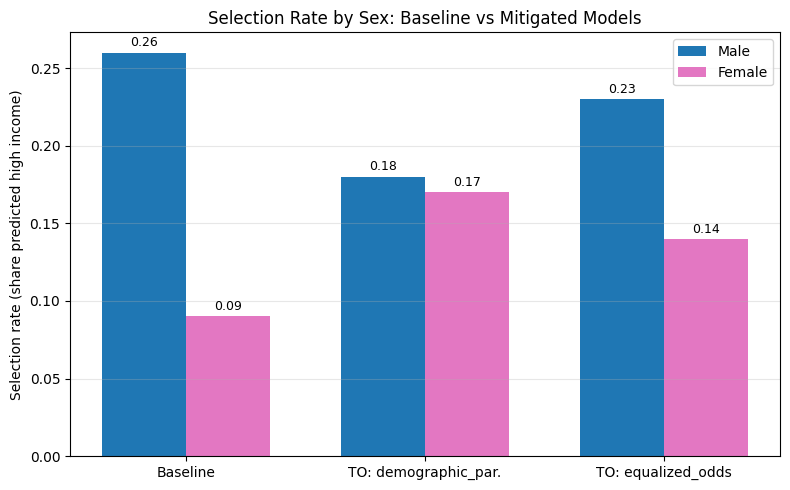

In [30]:
# Define layout and data helpers
labels = comp.index.tolist()
x_coords = np.arange(len(labels))
bar_width = 0.35

# Initialize the figure
fig, ax = plt.subplots(figsize=(8, 5))

# Plot male and female selection rates
male_bars = ax.bar(x_coords - bar_width/2, comp['SEL_M'], bar_width, label='Male', color='#1f77b4')
female_bars = ax.bar(x_coords + bar_width/2, comp['SEL_F'], bar_width, label='Female', color='#e377c2')

# Helper function to place labels nicely on top of bars
def label_bars(bars):
    for bar in bars:
        height = bar.get_height()
        x_pos = bar.get_x() + bar.get_width() / 2
        ax.text(x_pos, height + 0.004, f"{height:.2f}", ha='center', va='bottom', fontsize=9)

label_bars(male_bars)
label_bars(female_bars)

# Set labels, titles, and grid styling
ax.set_xticks(x_coords)
ax.set_xticklabels(labels)
ax.set_ylabel('Selection rate (share predicted high income)')
ax.set_title('Selection Rate by Sex: Baseline vs Mitigated Models')
ax.legend()
ax.grid(axis='y', alpha=0.3)

# Tighten layout and export
plt.tight_layout()
plt.savefig('selection_rate_by_sex.png', dpi=150)
plt.show()

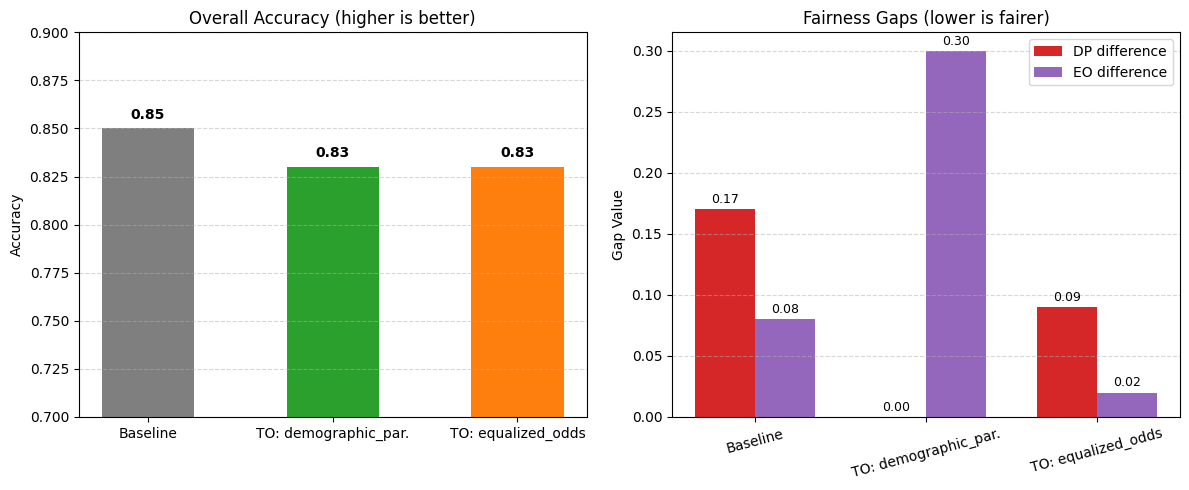

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
labels, xx, w = comp.index.tolist(), np.arange(len(comp)), 0.35

# Subplot 1: Overall Accuracy
bars = ax[0].bar(labels, comp["ACC"], color=["#7f7f7f", "#2ca02c", "#ff7f0e"], width=0.5)
ax[0].set_ylim(0.7, 0.9); ax[0].set_title("Overall Accuracy (higher is better)"); ax[0].set_ylabel("Accuracy")
for b in bars: ax[0].text(b.get_x() + b.get_width()/2, b.get_height() + 0.005, f"{b.get_height():.2f}", ha="center", fontweight="bold")

# Subplot 2: Fairness Gaps
b_dp = ax[1].bar(xx - w/2, comp["DP_DIFF"], w, label="DP difference", color="#d62728")
b_eo = ax[1].bar(xx + w/2, comp["EO_DIFF"], w, label="EO difference", color="#9467bd")
ax[1].set_xticks(xx); ax[1].set_xticklabels(labels, rotation=15)
ax[1].set_title("Fairness Gaps (lower is fairer)"); ax[1].set_ylabel("Gap Value"); ax[1].legend()
for b in list(b_dp) + list(b_eo): ax[1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.005, f"{b.get_height():.2f}", ha="center", fontsize=9)

for a in ax: a.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout(); plt.savefig("accuracy_vs_fairness.png", dpi=150); plt.show()